# 11장 의미 다양성과 대표성 판단

8장은 다양성을 TF-IDF SVD 임베딩의 거리로 쟀다. 표현이 다른데 같은 사건을 말하는 두 제목은 거리로 잡히지 않고, 뜻이 없는 문장은 거리로 보면 오히려 독특한 샘플이다. 이 장은 Jev에게 문장의 뜻으로 세 가지를 판정하게 한다.

- 의미 중복: 후보끼리 같은 사건·같은 의견을 말하는가
- 저품질·이상치: 라벨을 정할 수 없는 문장인가
- 대표성: 데이터에 흔한 유형인가

먼저 루프 없이 Jev의 중복·저품질 판정을 평가하고, 그다음 8장의 클러스터와 루프에서 비교한다. 비교 조건은 질의 크기 k = 50과 k = 200 둘이다.

- 11.1 정보성·대표성·다양성의 세 기준
- 11.2 의미 중복 판정
- 11.3 이상치와 저품질 샘플 필터링
- 11.4 임베딩 기반 다양성과 Jev 판단의 비교
- 11.5 결합 질의 선택기

학생 모델은 TF-IDF·로지스틱 회귀, 예산은 라벨 2,000개, 라벨은 시뮬레이션 사람 오라클이 붙인다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


3장의 엔트로피, 4장의 배깅 KL, 8장의 클러스터와 배치 중복 지표를 다시 싣는다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

In [3]:
# ── 4장 배깅 위원회와 KL 불일치 ────
def train_bagging_committee(X, y, C, seed):
    rng = np.random.default_rng(seed)
    boots = [rng.choice(len(y), len(y)) for _ in range(C)]
    return [train_model(X[b], y[b], seed + c) for c, b in enumerate(boots)]

def committee_proba(members, X, n_classes):
    return np.stack([proba(m, X, n_classes) for m in members])

def score_kl(PC):
    Pm = PC.mean(0)
    return (PC * (np.log(PC + 1e-12) - np.log(Pm + 1e-12))).sum(2).mean(0)

def query_bagging_kl(model, data, idx_l, y_l, idx_u, k, rng):
    members = train_bagging_committee(data["X_pool"][idx_l], y_l, 5, int(rng.integers(2**31)))
    s = score_kl(committee_proba(members, data["X_pool"][idx_u], data["n_classes"]))
    return idx_u[np.argsort(-s)[:k]]

# ── 배치 중복 지표(8장) ────
def batch_redundancy(X, idx, k=K, n_init=N_INIT, thr=0.9):
    rows = []
    for r, start in enumerate(range(n_init, len(idx), k)):
        S = (X[idx[start:start + k]] @ X[idx[start:start + k]].T).toarray()
        iu = np.triu_indices(len(S), 1)
        rows.append(dict(round=r, R=S[iu].mean(), dup=(S[iu] > thr).sum()))
    return pd.DataFrame(rows)

def run_with_order(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # run_strategies와 같고 라벨 순서도 돌려준다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    res = pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)
    return res, {job: idx for job, (_, idx) in zip(jobs, out)}

In [4]:
# ── 다양성 임베딩과 클러스터 질의(8장) ────
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

for d in DATA.values():
    Z = TruncatedSVD(256, random_state=42).fit(d["X_pool"]).transform(d["X_pool"]).astype(np.float32)
    d["Z"] = Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)

def query_cluster(model, data, idx_l, y_l, idx_u, k, rng, m=10):
    h = score_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"]))
    top = np.argsort(-h)[:m * k]
    lab = KMeans(k, n_init=1, random_state=int(rng.integers(2**31))).fit_predict(data["Z"][idx_u[top]])
    pick = [top[lab == c][np.argmax(h[top[lab == c]])] for c in range(k)]
    return idx_u[np.array(pick)]

## 11.1 정보성·대표성·다양성의 세 기준

정보성은 학생 모델이 그 샘플에서 얼마나 배우는가, 대표성은 그 샘플이 풀의 얼마나 많은 샘플을 닮았는가, 다양성은 배치 안 샘플들이 서로 얼마나 다른가다. 1부의 불확실성 점수는 정보성만 보고, 8장의 클러스터·코어셋은 임베딩 거리로 다양성을 본다. 이 장은 세 기준을 Jev의 판정 질문으로 받는다.

Jev 호출 함수와 라벨 체계는 10장과 같다.

In [5]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64):                       # 일시 오류(429·5xx)는 잠시 쉬고 다시 보낸다
        r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                         json=body, timeout=300)
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


In [6]:
# ── 라벨 체계 ────
LABEL_NAMES = {"nsmc": ["부정", "긍정"],
               "ynat": ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]}
LABEL_DESC = {"nsmc": {"부정": "영화를 부정적으로 평가한 리뷰", "긍정": "영화를 긍정적으로 평가한 리뷰"},
              "ynat": {"IT과학": "정보기술·과학 기사", "경제": "경제·산업·금융 기사", "사회": "사건·사고·사회 기사",
                       "생활문화": "생활·문화·건강·여행 기사", "세계": "국제·해외 기사", "스포츠": "스포츠 기사",
                       "정치": "정치·외교·북한 기사"}}
TASK = {"nsmc": "영화 리뷰의 감성", "ynat": "뉴스 기사 제목의 주제"}

판정 질문 셋을 만든다. 후보를 50개씩 묶어 번호를 붙이고 후보마다 필요한 질문만 붙인다.

- `dup_i` (choice): i번과 같은 사건이나 같은 의견을 말하는 다른 문장의 번호. 선택지는 다른 번호 49개와 「없음」이다.
- `lowq_i` (noul): i번 문장이 뜻이 없거나 라벨을 정할 수 없는 문장인가.
- `rep_i` (score): i번 같은 문장이 이 데이터에 얼마나 흔한가. 0 「드물다」부터 3 「매우 흔하다」까지다.

`dup_i` 의 답이 「없음」이 아니고 그 확률이 0.5 이상이면 두 문장을 잇는다. 이어진 문장들의 연결 성분이 의미 중복 묶음이다. 묶음은 같은 50개 묶음 안에서만 만들어진다.

In [7]:
# ── 의미 판정 질문 ────
CHUNK = 50

def q_dup(i, n):
    crit = {"없음": "목록에 이 문장과 같은 내용을 말하는 다른 문장이 없다"}
    crit.update({str(j): None for j in range(n) if j != i})
    return {"type": "choice", "criteria": crit,
            "instructions": f"[{i}]번 문장과 같은 사건이나 같은 의견을 말하는 다른 문장은 몇 번인가? 표현이 달라도 내용이 같으면 같은 것으로 본다."}

def q_lowq(data, i):
    return {"type": "noul", "instructions": f"[{i}]번 문장은 뜻이 없거나 {TASK[data['name']]}을 정할 수 없는 문장인가?"}

def q_rep(data, i):
    return {"type": "score", "criteria": ["드물다", "가끔 있다", "흔하다", "매우 흔하다"],
            "instructions": f"[{i}]번 같은 문장이 {TASK[data['name']]} 데이터에 얼마나 흔한 유형인가?"}

def judge_div(data, cand, need):
    n_all = len(cand)
    out = dict(edges=[], lowq=np.full(n_all, np.nan), rep=np.full(n_all, np.nan), n_in=0, n_out=0, calls=0)
    for s in range(0, n_all, CHUNK):
        part = cand[s:s + CHUNK]
        n = len(part)
        state = "\n".join(f"[{i}] " + str(t).replace("\n", " ") for i, t in enumerate(data["texts"][part]))
        qs = {}
        for i in range(n):
            qs.update({f"dup_{i}": q_dup(i, n)} if "dup" in need else {})
            qs.update({f"lowq_{i}": q_lowq(data, i)} if "lowq" in need else {})
            qs.update({f"rep_{i}": q_rep(data, i)} if "rep" in need else {})
        ans, a, b = jev_ask(state, qs)
        out["n_in"], out["n_out"], out["calls"] = out["n_in"] + a, out["n_out"] + b, out["calls"] + 1
        dup = [ans[f"dup_{i}"] for i in range(n)] if "dup" in need else []
        out["edges"] += [(s + i, s + int(c["choice"])) for i, c in enumerate(dup)
                         if c["choice"] != "없음" and c["probabilities"].get(c["choice"], 0) >= 0.5]
        out["lowq"][s:s + n] = [ans[f"lowq_{i}"]["noul"] for i in range(n)] if "lowq" in need else np.nan
        out["rep"][s:s + n] = [ans[f"rep_{i}"]["score"] for i in range(n)] if "rep" in need else np.nan
    return out

def components(n, edges):
    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for a, b in edges:
        parent[find(a)] = find(b)
    return np.array([find(i) for i in range(n)])

## 11.2 의미 중복 판정

루프 없이 Jev의 중복 판정부터 평가한다. 8장 실험의 시드 0을 다시 돌려 배깅 KL과 Random이 고른 배치(라운드마다 50개, 38개 배치)를 얻는다. 같은 환경과 시드라 8장과 같은 배치가 나온다. 배치마다 `dup` 질문을 보내 묶음을 만들고 원래 TF-IDF 코사인 유사도와 대조한다.

정답 중복 목록은 없으므로 두 가지를 본다. 하나는 코사인 0.9를 넘는 근접 중복 쌍을 Jev가 같은 묶음에 넣은 비율(근접 중복 재현율)이다. 다른 하나는 Jev가 직접 이은 쌍의 코사인 분포다. 코사인이 낮은데 Jev가 이은 쌍은 표현이 다르고 내용이 같은 중복일 수도, Jev의 오판일 수도 있다. 원문을 보고 판단한다.

In [8]:
# ── 중복 판정 정적 평가 ────
def static_eval(d):
    _, orders = run_with_order({"배깅5·KL": query_bagging_kl, "Random": query_random}, d, seeds=[0])
    rows, pairs = [], []
    for (strat, _), idx in orders.items():
        for r, start in enumerate(range(N_INIT, len(idx), K)):
            b = idx[start:start + K]
            J = judge_div(d, b, ("dup",))
            S = (d["X_pool"][b] @ d["X_pool"][b].T).toarray()
            comp = components(len(b), J["edges"])
            E = sorted({tuple(sorted(e)) for e in J["edges"] if e[0] != e[1]})   # 순서 없는 쌍으로 한 번씩
            iu = np.triu_indices(len(b), 1)
            hi = S[iu] > 0.9
            rows.append(dict(strategy=strat, round=r, hi_pairs=hi.sum(), hi_linked=(comp[iu[0]] == comp[iu[1]])[hi].sum(),
                             jev_edges=len(E), groups=len(b) - len(set(comp)), n_in=J["n_in"]))
            pairs += [dict(strategy=strat, round=r, i=b[a], j=b[c], cos=S[a, c]) for a, c in E]
    return pd.DataFrame(rows), pd.DataFrame(pairs)

os.makedirs("results/ch11_parts", exist_ok=True)
static = {}
for name, d in DATA.items():
    path = f"results/ch11_parts/static_{name}"                 # 다시 실행할 때 Jev를 다시 부르지 않도록 저장한다
    if not os.path.exists(path + "_batch.csv"):
        t, p = static_eval(d)
        t.to_csv(path + "_batch.csv", index=False)
        p.to_csv(path + "_pairs.csv", index=False)
    static[name] = (pd.read_csv(path + "_batch.csv"), pd.read_csv(path + "_pairs.csv"))
    t, p = static[name]
    g = t.groupby("strategy", sort=False).agg(hi_pairs=("hi_pairs", "sum"), hi_linked=("hi_linked", "sum"),
                                               jev_edges=("jev_edges", "sum"), merged=("groups", "mean"), n_in=("n_in", "mean"))
    g["recall_hi"] = (g.hi_linked / g.hi_pairs).round(4)
    g["edge_cos_median"] = p.groupby("strategy", sort=False).cos.median().round(4)
    g["edge_cos_lt_0.3"] = p.assign(lo=p.cos < 0.3).groupby("strategy", sort=False).lo.mean().round(4)
    print(f"\n{name} 중복 판정 (시드 0, 배치 38개씩; merged는 배치당 묶여 줄어든 문장 수)")
    print(g.to_string())


nsmc 중복 판정 (시드 0, 배치 38개씩; merged는 배치당 묶여 줄어든 문장 수)
          hi_pairs  hi_linked  jev_edges    merged          n_in  recall_hi  edge_cos_median  edge_cos_lt_0.3
strategy                                                                                                     
배깅5·KL           7          0          5  0.131579  22636.894737        0.0            0.075              0.6
Random           0          0          0  0.000000  23200.973684        NaN              NaN              NaN

ynat 중복 판정 (시드 0, 배치 38개씩; merged는 배치당 묶여 줄어든 문장 수)
          hi_pairs  hi_linked  jev_edges    merged          n_in  recall_hi  edge_cos_median  edge_cos_lt_0.3
strategy                                                                                                     
배깅5·KL          18         13         85  2.236842  22789.447368     0.7222           0.0241           0.6000
Random           0          0          6  0.157895  22901.657895        NaN           0.0216           0.8333



nsmc: Jev가 이었지만 코사인이 가장 낮은 쌍
  0.000 | 너무 잼떠용 | 영화 예고편이 제일 무서워요!
  0.003 | 처음엔 재밌을 줄 알았는데 내용이 좀 지저분해요. | 아이들이 너무 너무 좋아하네요 . 귀엽고 ㅋㅋㅋ 볼만합니다~~
  0.075 | 1편보다 많이 떨어진다. | 1편이 너무좋아서 2편이 너무묻힌다
  0.391 | 보고 싶은데 어디서 볼수있을까 | 이 영화 보고싶은데 어디서 구할 수 있나요?
nsmc: 코사인이 가장 높은 쌍
  0.465 | 이거 개봉했나요? 예전에 우연히 예고편 본적있어서 점 찍어 뒀던 영화 | 이 영화는 도대체 어디서 볼 수 있나요? ㅠ
  0.391 | 보고 싶은데 어디서 볼수있을까 | 이 영화 보고싶은데 어디서 구할 수 있나요?

ynat: Jev가 이었지만 코사인이 가장 낮은 쌍
  0.000 | 중국인들 경제불안·IS보다 무서운 건 미국 영향력 | 선서문 든 김동연 부총리
  0.000 | 경기 남·북부권 13개 시·군 오후 2시 오존주의보 | LG전자 새 중저가폰 X400 내주 출시…핑거터치 기능
  0.000 | 경기 남·북부권 13개 시·군 오후 2시 오존주의보 | LG전자 중저가폰 X400 출시…31만9천원
  0.000 | MBC 신임 보도국장에 박성제씨 내정…임명동의제 도입종합 | 그래픽 애플 세계 스마트폰 영업이익 79％ 독식
ynat: 코사인이 가장 높은 쌍
  0.975 | 새누리 이번엔 예비후보 사전여론조사 결과 유출 논란 | 새누리 이번엔 예비후보 사전여론조사 결과 유출 논란종합
  0.958 | 경기방송몽골 국영방송 교류증진 MOU 체결 | 경기소식 경기방송몽골 국영방송 교류증진 MOU 체결


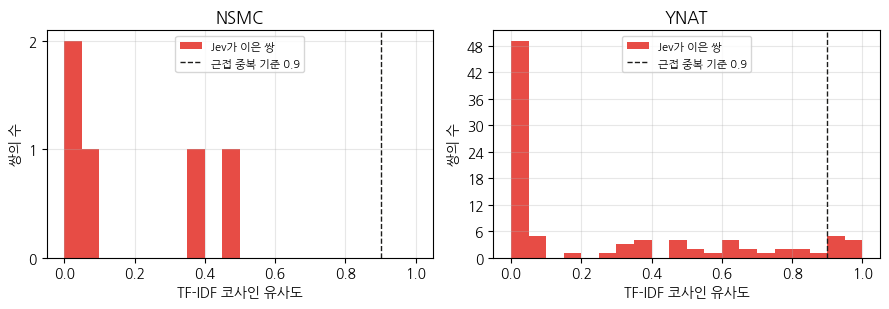

In [9]:
# ── Jev가 이은 쌍의 코사인 분포와 사례 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (name, (t, p)) in zip(axes, static.items()):
    ax.hist(p.cos, bins=np.linspace(0, 1, 21), color=ACCENT, alpha=0.85, label="Jev가 이은 쌍")
    ax.axvline(0.9, color=INK, ls="--", lw=1, label="근접 중복 기준 0.9")
    ax.set(title=name.upper(), xlabel="TF-IDF 코사인 유사도", ylabel="쌍의 수")
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("out/ch11_dup_cos.png", dpi=200)

for name, (t, p) in static.items():
    d = DATA[name]
    print(f"\n{name}: Jev가 이었지만 코사인이 가장 낮은 쌍")
    for _, e in p.nsmallest(4, "cos").iterrows():
        print(f"  {e.cos:.3f} | {str(d['texts'][int(e.i)])[:38]} | {str(d['texts'][int(e.j)])[:38]}")
    print(f"{name}: 코사인이 가장 높은 쌍")
    for _, e in p.nlargest(2, "cos").iterrows():
        print(f"  {e.cos:.3f} | {str(d['texts'][int(e.i)])[:38]} | {str(d['texts'][int(e.j)])[:38]}")

## 11.3 이상치와 저품질 샘플 필터링

시드 0의 초기 라벨 100개로 학습한 모델에서 엔트로피 상위 150개를 뽑아 `lowq` 와 `rep` 을 묻는다. 저품질 확률이 0.5 이상인 문장이 몇 개인지, 어떤 문장인지, 학생 모델이 그 문장들을 얼마나 맞히는지 본다.

In [10]:
# ── 저품질·대표성 판정 정적 평가 ────
for name, d in DATA.items():
    rng = np.random.default_rng(0)
    idx_l = rng.choice(len(d["y_pool"]), N_INIT, replace=False)
    m = train_model(d["X_pool"][idx_l], d["y_pool"][idx_l], 0)
    idx_u = np.setdiff1d(np.arange(len(d["y_pool"])), idx_l)
    P = proba(m, d["X_pool"][idx_u], d["n_classes"])
    top = np.argsort(-score_entropy(P))[:3 * K]
    cand = idx_u[top]
    J = judge_div(d, cand, ("lowq", "rep"))
    low = J["lowq"] >= 0.5
    ok = P[top].argmax(1) == d["y_pool"][cand]
    print(f"\n{name}: 후보 150개 중 저품질 {low.sum()}개 | 학생 정답률 저품질 {ok[low].mean():.4f}, 나머지 {ok[~low].mean():.4f}"
          f" | 대표성 점수 분포 {np.percentile(J['rep'], [0, 25, 50, 75, 100]).round(2)} | 입력 토큰 {J['n_in']}")
    for i in np.argsort(-J["lowq"])[:5]:
        print(f"  저품질 {J['lowq'][i]:.2f} | 정답 {LABEL_NAMES[name][d['y_pool'][cand[i]]]} | {str(d['texts'][cand[i]])[:50]}")
    print("  대표성 높은 문장:", [str(d["texts"][cand[i]])[:25] for i in np.argsort(-J["rep"])[:3]])
    print("  대표성 낮은 문장:", [str(d["texts"][cand[i]])[:25] for i in np.argsort(J["rep"])[:3]])


nsmc: 후보 150개 중 저품질 20개 | 학생 정답률 저품질 0.2500, 나머지 0.4692 | 대표성 점수 분포 [0.22 1.1  1.39 1.64 2.36] | 입력 토큰 22449
  저품질 0.81 | 정답 긍정 | 캐스팅도 스토리도
  저품질 0.79 | 정답 긍정 | UMF너무 가고싶어요
  저품질 0.76 | 정답 긍정 | 마이애미가 예쁜여자들은 가장 많이 나옴.
  저품질 0.74 | 정답 긍정 | 성인영화배우님들 파이팅! 자신감을 가지세요
  저품질 0.66 | 정답 긍정 | 난 왜 음악만들어도 심장이 터질것같을까...
  대표성 높은 문장: ['언제봐도 감동입니다..', '짱재밌오요~~^^♥♥♥♥♥♥♥♥♥♥!', '최고, 최고, 또최고..']
  대표성 낮은 문장: ['성인영화배우님들 파이팅! 자신감을 가지세요', '보조금에 대한 안좋은 기사가 있네요..', 'UMF너무 가고싶어요']



ynat: 후보 150개 중 저품질 1개 | 학생 정답률 저품질 0.0000, 나머지 0.1544 | 대표성 점수 분포 [0.4  1.45 1.83 2.1  2.62] | 입력 토큰 21848
  저품질 0.51 | 정답 IT과학 | 홈런 장면 10초 먼저…KT 5G IT 에지 클라우드 구축
  저품질 0.36 | 정답 세계 | 中 홍콩 언급하며 이익 해치는 쓴 열매 안 삼킬 것 경고
  저품질 0.33 | 정답 경제 | 지원금 상한제 폐지 한달 ① 소비자 혜택은 없었다
  저품질 0.21 | 정답 세계 | 中 G7 홍콩 자치 지지 언급에 쓸데없는 참견 말라
  저품질 0.20 | 정답 경제 | 작년 12월 산업생산 1.2% 증가…소비는 두 달째 감소종합2보
  대표성 높은 문장: ['LG생활건강 3분기 영업이익 2천441억원…2', 'LG디스플레이 2분기 영업이익 444억…90.', '롯데쇼핑 3분기 영업이익 876억원…작년 동기']
  대표성 낮은 문장: ['우주질량 80% 차지한 암흑물질 정체 밝혀지나', '백남준 알렉산더 대왕 홍콩 경매 출품', '中 홍콩 언급하며 이익 해치는 쓴 열매 안 삼']


## 11.4 임베딩 기반 다양성과 Jev 판단의 비교

Jev 판정을 쓰는 질의 함수 셋을 만든다. 후보는 모두 엔트로피 상위 3k개다.

| 전략 | 점수 s(x) | 묶음 |
|---|---|---|
| 엔트로피·Jev 필터 | 엔트로피, 저품질(≥ 0.5)이면 맨 뒤로 | 없음 |
| Jev 의미 다양성 | 엔트로피 | dup 묶음마다 하나 |
| 결합 선택기 | 엔트로피 × (1 − 저품질 확률) × (1 + 대표성/3) | dup 묶음마다 하나 |

묶음이 있으면 묶음마다 점수가 가장 높은 샘플 하나를 대표로 남기고, 대표를 점수 순으로 k개 고른다. 대표가 k개보다 적으면 남은 후보를 점수 순으로 채운다.

In [11]:
# ── Jev 의미 판정 질의 함수 ────
NEED = {"filter": ("lowq",), "dedup": ("dup",), "combo": ("dup", "lowq", "rep")}

def pick_by_group(s, g, k):
    order = np.argsort(-s, kind="stable")
    first = order[~pd.Series(g[order]).duplicated().values]          # 묶음마다 점수 최대 하나
    return np.r_[first, order[~np.isin(order, first)]][:k]

def make_div_query(mode, m=3):
    stats = []
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        h = score_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"]))
        top = np.argsort(-h)[:m * k]
        perm = rng.permutation(len(top))                              # 묶음을 섞은 순서로 만든다
        cand, hc = idx_u[top][perm], h[top][perm]
        t0 = time.perf_counter()
        J = judge_div(data, cand, NEED[mode])
        lowq, rep = np.nan_to_num(J["lowq"]), np.nan_to_num(J["rep"])
        s = {"filter": hc - 100 * (lowq >= 0.5), "dedup": hc, "combo": hc * (1 - lowq) * (1 + rep / 3)}[mode]
        g = components(len(cand), J["edges"]) if "dup" in NEED[mode] else np.arange(len(cand))
        sel = pick_by_group(s, g, k)
        stats.append(dict(n_in=J["n_in"], n_out=J["n_out"], calls=J["calls"], t_jev=time.perf_counter() - t0,
                          n_low=int((lowq >= 0.5).sum()), merged=len(cand) - len(set(g))))
        return cand[sel]
    query_fn.stats = stats
    return query_fn

k = 50과 k = 200 두 조건에서 다섯 전략(엔트로피, 클러스터, 엔트로피·Jev 필터, Jev 의미 다양성, 결합 선택기)과 Random을 돌린다. 기준선은 CPU 코어에 나눠 돌리고, Jev 전략은 시드 5개를 스레드로 동시에 돌린다. Jev 전략의 결과와 라벨 순서는 `results/ch11_parts/` 에 저장한다. 배치 중복 R(Q)는 모든 전략의 라벨 순서로 8장과 같은 방식으로 잰다.

In [12]:
# ── 루프 실험: k = 50, 200 ────
os.makedirs("results/ch11_parts", exist_ok=True)

def run_div(name, mode, k, d, seed):
    path = f"results/ch11_parts/{d['name']}_{mode}_k{k}_{seed}"
    if os.path.exists(path + ".csv"):
        return pd.read_csv(path + ".csv"), np.load(path + ".npy")
    q = make_div_query(mode)
    t0 = time.perf_counter()
    df, idx = run_loop(q, make_sim_oracle(d["y_pool"]), d, seed, k=k)
    df = pd.concat([df, pd.DataFrame(q.stats)], axis=1).assign(strategy=name, wall=time.perf_counter() - t0)
    df.to_csv(path + ".csv", index=False)
    np.save(path + ".npy", idx)
    return df, idx

DIV = {"엔트로피·Jev 필터": "filter", "Jev 의미 다양성": "dedup", "결합 선택기": "combo"}
BASE = {"Random": query_random, "엔트로피": query_entropy, "클러스터": query_cluster}
res, red = {}, []
for name, d in DATA.items():
    for k in (50, 200):
        t0 = time.perf_counter()
        r, orders = run_with_order(BASE, d, k=k)
        frames = [r]
        for s, mode in DIV.items():
            with ThreadPoolExecutor(MAX_CONC) as ex:
                out = list(ex.map(lambda sd: run_div(s, mode, k, d, sd), SEEDS))
            frames += [df for df, _ in out]
            orders.update({(s, sd): idx for sd, (_, idx) in zip(SEEDS, out)})
        res[name, k] = pd.concat(frames, ignore_index=True)
        red += [batch_redundancy(d["X_pool"], idx, k=k).assign(data=name, k=k, strategy=s, seed=sd) for (s, sd), idx in orders.items()]
        print(f"{name} k={k} 완료 {(time.perf_counter() - t0) / 60:.1f}분")
red = pd.concat(red, ignore_index=True)

nsmc  Random, 엔트로피, 클러스터 완료


nsmc k=50 완료 1.1분


nsmc  Random, 엔트로피, 클러스터 완료


nsmc k=200 완료 0.7분


ynat  Random, 엔트로피, 클러스터 완료


ynat k=50 완료 14.0분


ynat  Random, 엔트로피, 클러스터 완료


ynat k=200 완료 3.0분


## 11.5 결합 질의 선택기

다섯 전략의 ALC(평균과 시드 범위), 배치 중복, Jev 호출량을 함께 본다. 라벨 효율의 기준은 Random의 라벨 2,000 성능이다.


nsmc k=50 매크로 F1 (R·dup는 배치 평균, n_low·merged는 라운드 평균)
                ALC  ALC_std   final      LE  t_query  ALC_min  ALC_max       R     dup     n_in  calls  n_low  merged
strategy                                                                                                              
Random       0.7426   0.0034  0.7802  1.0000   0.0005   0.7359   0.7448  0.0094  0.0000      NaN    NaN    NaN     NaN
엔트로피         0.7479   0.0055  0.7860  1.2121   0.0536   0.7387   0.7529  0.0086  0.0316      NaN    NaN    NaN     NaN
클러스터         0.7464   0.0019  0.7854  1.1429   0.1947   0.7443   0.7490  0.0077  0.0000      NaN    NaN    NaN     NaN
엔트로피·Jev 필터  0.7501   0.0035  0.7880  1.2500   0.6325   0.7466   0.7567  0.0100  0.0316  11040.7    3.0   34.2     0.0
Jev 의미 다양성   0.7479   0.0055  0.7860  1.2121   0.9513   0.7387   0.7529  0.0086  0.0316  69616.1    3.0    0.0     0.2
결합 선택기       0.7623   0.0036  0.7997  1.7391   1.0661   0.7566   0.7678  0.0121  0.0000  85943.9    3.0   37.7  

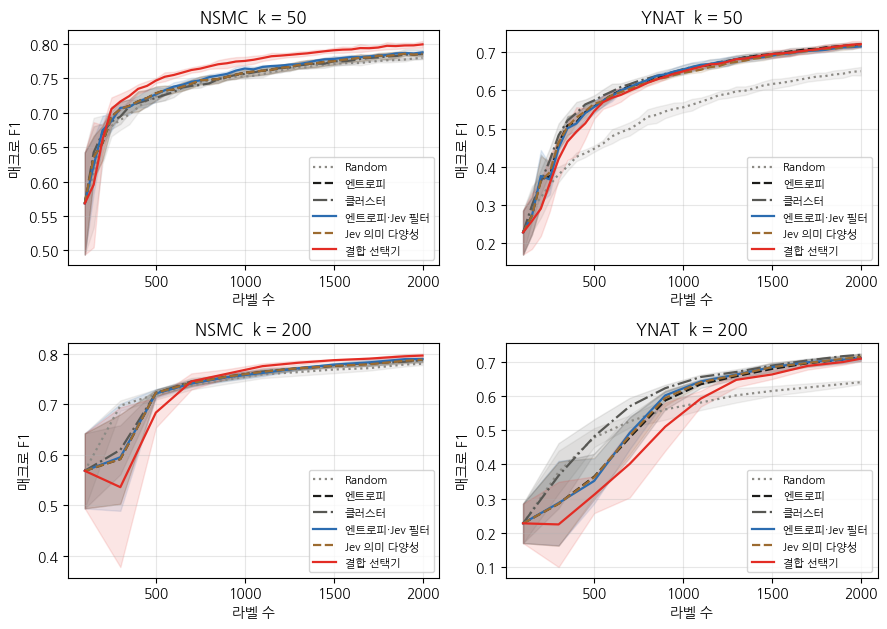

In [13]:
# ── 결과 표와 학습 곡선 ────
STYLES = [(GRAY2, ":"), (INK, "--"), (GRAY, "-."), ("#2B6CB0", "-"), ("#9C6B30", "--"), (ACCENT, "-")]

def alc_range(r, metric="f1"):
    a = r.groupby(["strategy", "seed"], sort=False).apply(lambda g: alc(g.n_labeled.values, g[metric].values), include_groups=False)
    return a.groupby(level=0, sort=False).agg(ALC_min="min", ALC_max="max").round(4)

for (name, k), r in res.items():
    t = summarize(r, "f1").set_index("strategy").join(alc_range(r))
    t = t.join(red[(red.data == name) & (red.k == k)].groupby("strategy")[["R", "dup"]].mean().round(4))
    j = r[r.n_in.notna()].groupby("strategy", sort=False)[["n_in", "calls", "n_low", "merged"]].mean().round(1)
    print(f"\n{name} k={k} 매크로 F1 (R·dup는 배치 평균, n_low·merged는 라운드 평균)")
    print(t.join(j).to_string())

fig, axes = plt.subplots(2, 2, figsize=(9, 6.4))
for ax, ((name, k), r) in zip(axes.T.ravel(), res.items()):
    plot_curves(r, "f1", ax, f"{name.upper()}  k = {k}")
fig.tight_layout()
fig.savefig("out/ch11_curves.png", dpi=200)

In [14]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
import glob
files = [f for f in glob.glob("results/ch11_parts/*.csv") if not f.endswith(("_picks.csv", "_log.csv"))]
total = sum(pd.read_csv(f).filter(regex="^n_in").sum().sum() for f in files)
print(f"결과 파일에 기록된 Jev 입력 토큰 합: {total:,.0f}")

결과 파일에 기록된 Jev 입력 토큰 합: 129,243,012
